# Занятие 8 — применяем BERT, сравниваем стадии GPT, обучаем LoRA

*NLP @ HSE DSBA · ADD-2026. Автор: Дарья Андреева.*

Практика по занятиям о BERT, GPT и дообучении. Код голов, выравнивания NER, окон QA, генерации и вычислений предпочтений перенесён из английских семинаров `autumn-2026`.

Основной маршрут: BERT для классификации → zero-shot через маску → головы NER и QA → base/SFT/DPO/RLVR одной модели → LoRA на GPT-2. Численные шаги PPO/DPO/GRPO — в конце.

Рядом с ноутбуком есть [интерактивная страница](https://xufana.github.io/dsba_nlp/add-2026/week08/). Английские тексты данных и ответы моделей сохранены в исходном виде.


## Подготовка

Для живого обучения выберите GPU в Colab. Ноутбук загружает только одну большую модель за раз. Короткий режим служит для проверки кода; качество оцениваем на сохранённых опытах с указанными условиями. Небольшая выборка не воспроизводит их итоговые оценки.

На CUDA по умолчанию включены BERT и LoRA. На CPU/MPS включите нужные этапы в настройках; сравнение четырёх генеративных чекпойнтов включается отдельно. Сохранённые результаты доступны без обучения и загрузки весов.


In [ ]:
# В Colab выполните эту ячейку один раз, затем при необходимости перезапустите среду.
# %pip install -q "transformers>=5.19,<6" "peft>=0.21,<0.22" "datasets>=5,<6" accelerate scikit-learn pandas matplotlib seqeval


In [ ]:
import gc
import json
import math
import random
import re
import time
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from datasets import Dataset, load_dataset
from transformers import (
    AutoTokenizer, AutoModel, AutoModelForMaskedLM,
    AutoModelForSequenceClassification, AutoModelForTokenClassification,
    AutoModelForQuestionAnswering, AutoModelForCausalLM,
    DataCollatorWithPadding, DataCollatorForTokenClassification,
)
from peft import LoraConfig, TaskType, get_peft_model, PeftModel
from IPython.display import display

SEED = 42
IGNORE = -100
MODEL_NAME = "bert-base-uncased"
CLASS_NAMES = ["World", "Sports", "Business", "Sci/Tech"]
NER_TAGS = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
ATTN = "eager"

RUN_BERT = device.type == "cuda"
RUN_BERT_TRAINING = device.type == "cuda"
RUN_GENERATION = False
RUN_LORA = device.type == "cuda"
N_TRAIN, N_TEST = 256, 128
BATCH_SIZE = 4
TRAIN_STEPS = 32
MAX_LENGTH = 128
OUTPUT_DIR = Path("/tmp/dsba_nlp/week08/practice")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def free():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    elif torch.backends.mps.is_available():
        torch.mps.empty_cache()


def n_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


seed_all()
print("Устройство:", device)
print("Обучение включается отдельно от загрузки моделей.")


In [ ]:
data_path = Path("practice_data.json")
if not data_path.exists():
    data_url = "https://raw.githubusercontent.com/xufana/dsba_nlp/ADD-2026/week08_practice/practice_data.json"
    urllib.request.urlretrieve(data_url, data_path)
DATA = json.loads(data_path.read_text())


print("Условия BERT:", DATA["bert"]["meta"])
print("Условия PEFT:", DATA["peft"]["meta"])
print("Условия alignment:", DATA["alignment"]["stages"]["n_gsm"], "задач GSM8K")


## 1. BERT: задача задаёт выход

BERT возвращает контекстный вектор для каждой позиции. Для метки текста берём один вектор и применяем линейную голову; для NER — одну и ту же голову к каждой позиции; для QA — две оценки на позицию: начало и конец ответа.

**Предположение:** скачали `AutoModelForSequenceClassification` из исходного BERT. Будут ли предсказания сразу полезными, если голова ещё не обучалась?

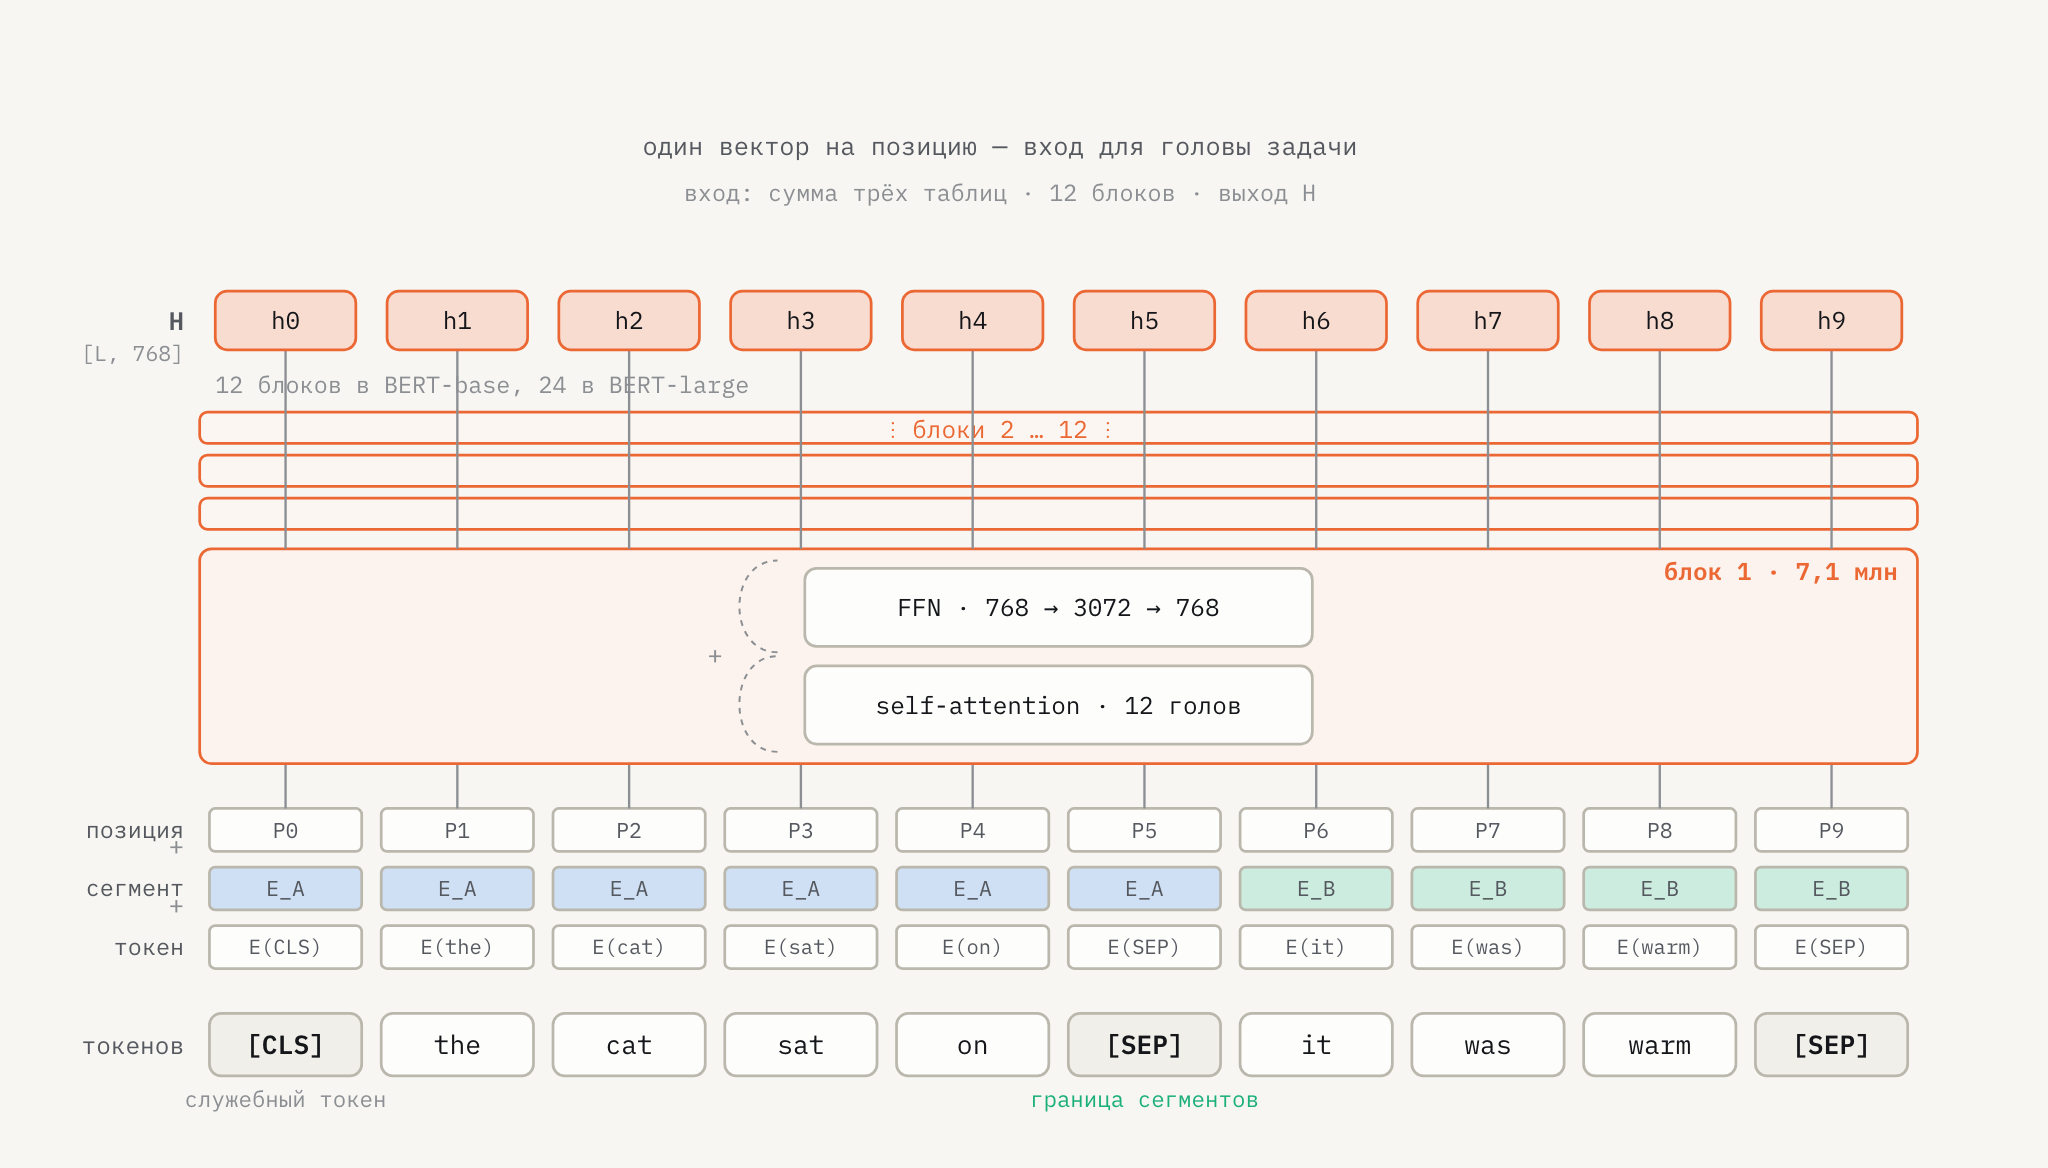

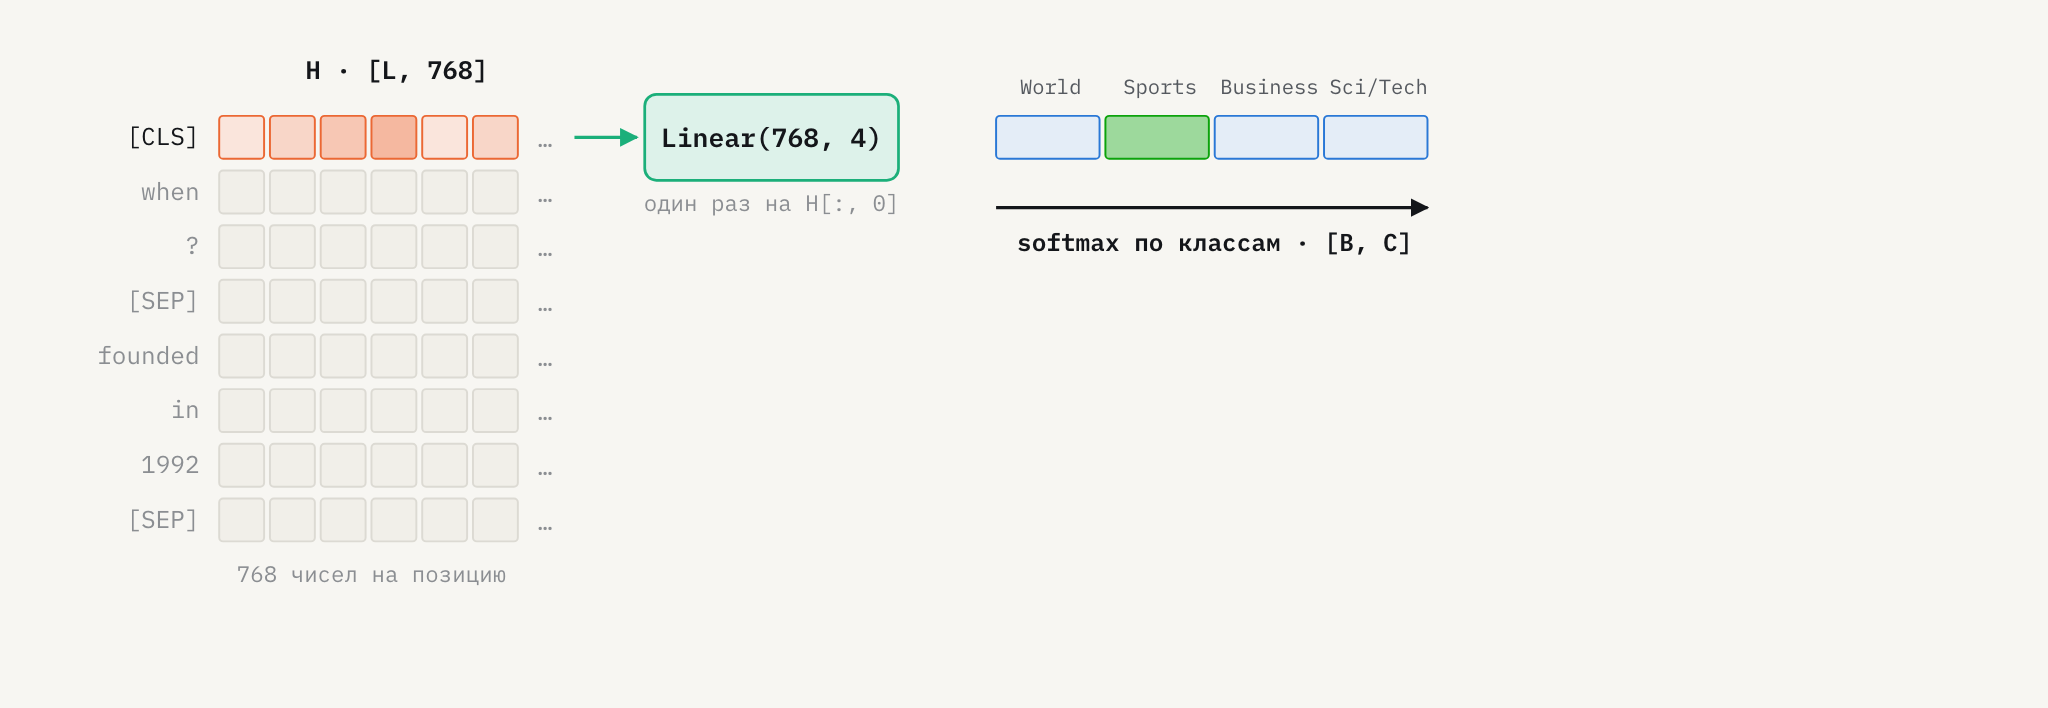


In [ ]:
class SequenceHead(nn.Module):

    def __init__(self, d, n_classes, dropout=0.1):
        super().__init__()
        self.drop = nn.Dropout(dropout)
        self.linear = nn.Linear(d, n_classes)

    def forward(self, H, attention_mask=None):
        return self.linear(self.drop(H[:, 0]))

class TokenHead(nn.Module):

    def __init__(self, d, n_classes, dropout=0.1):
        super().__init__()
        self.drop = nn.Dropout(dropout)
        self.linear = nn.Linear(d, n_classes)

    def forward(self, H, attention_mask=None):
        return self.linear(self.drop(H))

class SpanHead(nn.Module):

    def __init__(self, d, dropout=0.0):
        super().__init__()
        self.drop = nn.Dropout(dropout)
        self.linear = nn.Linear(d, 2)

    def forward(self, H, attention_mask=None):
        start, end = self.linear(self.drop(H)).unbind(-1)
        return (start, end)

def sequence_loss(logits, labels):
    return F.cross_entropy(logits, labels)

def token_loss(logits, labels):
    return F.cross_entropy(logits.flatten(0, 1), labels.flatten(), ignore_index=IGNORE)

def span_loss(scores, labels):
    start, end = scores
    return (F.cross_entropy(start, labels[:, 0]) + F.cross_entropy(end, labels[:, 1])) / 2


In [ ]:
H = torch.randn(2, 7, 24)
print("Метка текста:", SequenceHead(24, 4)(H).shape)
print("NER:", TokenHead(24, len(NER_TAGS))(H).shape)
print("QA:", [x.shape for x in SpanHead(24)(H)])
print("Ошибка NER:", token_loss(TokenHead(24, 9)(H), torch.tensor([[0, 1, -100, 0, 0, 0, -100]] * 2)).item())


### Загружаем модель и смотрим представления

`RUN_BERT = True` включает загрузку весов и данных. В выводе видны форма входа, скрытых состояний и распределения по четырём классам случайной головы. Сохраняйте одинаковый split и seed при сравнении методов.


In [ ]:
def set_trainable(model, top_blocks):
    body = model.base_model
    for p in body.parameters():
        p.requires_grad = top_blocks == 'all'
    if top_blocks != 'all' and top_blocks > 0:
        for block in body.encoder.layer[-top_blocks:]:
            for p in block.parameters():
                p.requires_grad = True
        if getattr(body, 'pooler', None) is not None:
            for p in body.pooler.parameters():
                p.requires_grad = True
    return model


In [ ]:
if RUN_BERT:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    ag = load_dataset("fancyzhx/ag_news")
    ag_train = ag["train"].shuffle(seed=SEED).select(range(N_TRAIN))
    ag_test = ag["test"].shuffle(seed=SEED).select(range(N_TEST))
    body = AutoModel.from_pretrained(MODEL_NAME, attn_implementation=ATTN).to(device).eval()
    example = tokenizer(ag_test[0]["text"], truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(device)
    with torch.no_grad():
        hidden = body(**example).last_hidden_state
    print("Вход:", example.input_ids.shape, "представления:", hidden.shape)
    del body, hidden, example
    free()
    seed_all()
    classifier = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=4, attn_implementation=ATTN).to(device).eval()
    with torch.no_grad():
        logits = classifier(**tokenizer(ag_test[0]["text"], truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(device)).logits
    print("Случайная голова:", logits.softmax(-1).cpu().numpy())
    del classifier, logits
    free()
else:
    print("Для загрузки BERT включите RUN_BERT.")


### Linear probing и полное дообучение

Один и тот же классификатор и данные. При linear probing меняется только линейная голова; при полном дообучении — и голова, и BERT. В замороженной модели отключаем dropout, чтобы признаки оставались неизменными.

**Предположение:** какой вариант быстрее улучшит результат на маленькой обучающей выборке? Запишите ожидание до запуска. Короткий опыт проверяет механизм, а не определяет лучший метод.


In [ ]:
def classification_data(tokenizer, train_data, test_data, text_column="text"):
    def encode(batch):
        return tokenizer(batch[text_column], truncation=True, max_length=MAX_LENGTH)
    datasets = []
    for split in (train_data, test_data):
        encoded = split.map(encode, batched=True, remove_columns=[c for c in split.column_names if c != "label"])
        datasets.append(encoded)
    collator = DataCollatorWithPadding(tokenizer, pad_to_multiple_of=8)
    return (
        DataLoader(datasets[0], batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator),
        DataLoader(datasets[1], batch_size=BATCH_SIZE, collate_fn=collator),
    )


@torch.no_grad()
def classification_score(model, loader):
    model.eval()
    correct = total = 0
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        pred = model(**batch).logits.argmax(-1)
        correct += (pred == batch["labels"]).sum().item()
        total += len(pred)
    return correct / total


def fit_classifier(model, loader, steps=TRAIN_STEPS, lr=2e-5, frozen_body=None):
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    step, losses, started = 0, [], time.monotonic()
    while step < steps:
        for batch in loader:
            model.train()
            if frozen_body is not None:
                frozen_body.eval()
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            loss = model(**batch).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(loss.item())
            step += 1
            elapsed = time.monotonic() - started
            print(f"\rШаг {step}/{steps} · ошибка {loss.item():.4f} · {step / elapsed:.2f} шаг/с · осталось {(steps-step)*elapsed/step:.0f} с · {device}", end="", flush=True)
            if step == steps:
                break
    print()
    model.eval()
    return losses


In [ ]:
if RUN_BERT and RUN_BERT_TRAINING:
    bert_train_loader, bert_test_loader = classification_data(tokenizer, ag_train, ag_test)
    rows = []
    for mode, top, lr in [("linear probing", 0, 1e-3), ("fine-tuning", "all", 2e-5)]:
        seed_all()
        classifier = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=4, attn_implementation=ATTN).to(device)
        set_trainable(classifier, top)
        before = classification_score(classifier, bert_test_loader)
        losses = fit_classifier(classifier, bert_train_loader, lr=lr, frozen_body=classifier.bert if top == 0 else None)
        rows.append({"метод": mode, "обучаемых": n_params(classifier, True), "до": before, "после": classification_score(classifier, bert_test_loader)})
        del classifier, losses
        free()
    display(pd.DataFrame(rows))
else:
    print("Живое сравнение: RUN_BERT = RUN_BERT_TRAINING = True.")

transfer = DATA["bert"]["transfer"]
print("Сохранённый опыт: BERT, AG News; условия:")
print({k: v for k, v in transfer.items() if k not in ["runs", "table"] and not isinstance(v, list)})
display(pd.DataFrame(transfer["runs"]).T if isinstance(transfer.get("runs"), dict) else transfer)


## 2. Zero-shot BERT через маску

Добавляем к новости `This news is about [MASK].` и сравниваем вероятности слов классов. Голова MLM уже обучалась предсказывать токены; новые параметры не обучаем.

**Предположение:** изменится ли качество, если заменить `world` на `politics` при том же корпусе и остальных словах классов? В интерактиве можно менять слова и пересчитывать предсказания на сохранённых вероятностях.


In [ ]:
def zero_shot_predict(probs, tokenizer, label_words):
    ids = tokenizer.convert_tokens_to_ids(label_words)
    assert tokenizer.unk_token_id not in ids, 'every label word has to be a single token'
    return probs[:, ids].argmax(-1).numpy()


In [ ]:
if RUN_BERT:
    mlm = AutoModelForMaskedLM.from_pretrained(MODEL_NAME, attn_implementation=ATTN).to(device).eval()
    texts = ag_test.select(range(min(32, len(ag_test))))
    distributions = []
    with torch.no_grad():
        for start in range(0, len(texts), BATCH_SIZE):
            chunk = texts[start:start+BATCH_SIZE]["text"]
            enc = tokenizer(chunk, ["This news is about [MASK]."] * len(chunk), truncation="only_first", max_length=MAX_LENGTH, padding=True, return_tensors="pt").to(device)
            positions = (enc.input_ids == tokenizer.mask_token_id).nonzero()[:, 1]
            hidden = mlm.bert(**enc).last_hidden_state
            masked_hidden = hidden[torch.arange(len(chunk), device=device), positions]
            distributions.append(mlm.cls(masked_hidden).softmax(-1).cpu())
    probabilities = torch.cat(distributions)
    for words in [["world", "sports", "business", "technology"], ["politics", "sports", "business", "technology"]]:
        pred = zero_shot_predict(probabilities, tokenizer, words)
        print(words, "точность:", float((pred == np.array(texts["label"])).mean()))
    del mlm, hidden, masked_hidden, enc, distributions, probabilities
    free()
else:
    print("Живой MLM: включите RUN_BERT. Сохранённые результаты:")
    display(DATA["bert"]["zeroShot"]["python"])


## 3. NER: метка слова и метки токенов

BIO различает начало и продолжение сущности. Одно слово может распасться на несколько токенов. Здесь метку получает первый токен слова, остальные и служебные позиции получают `-100`.

**Предположение:** почему обычная точность по токенам может быть высокой даже при плохом извлечении сущностей? Сравните с F1 по целым сущностям.

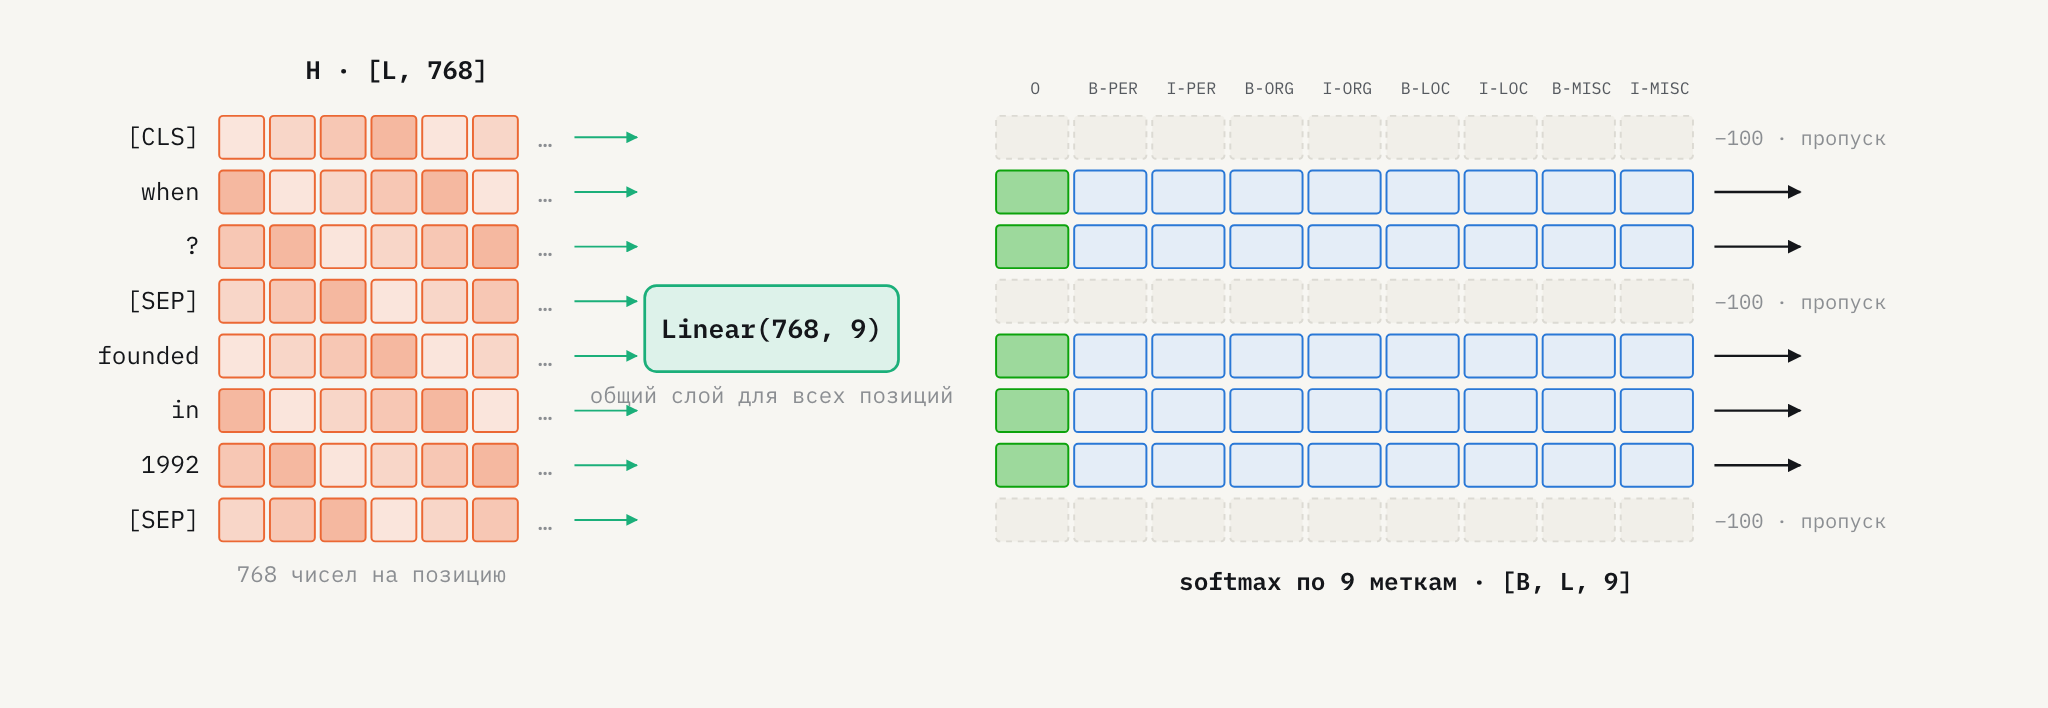

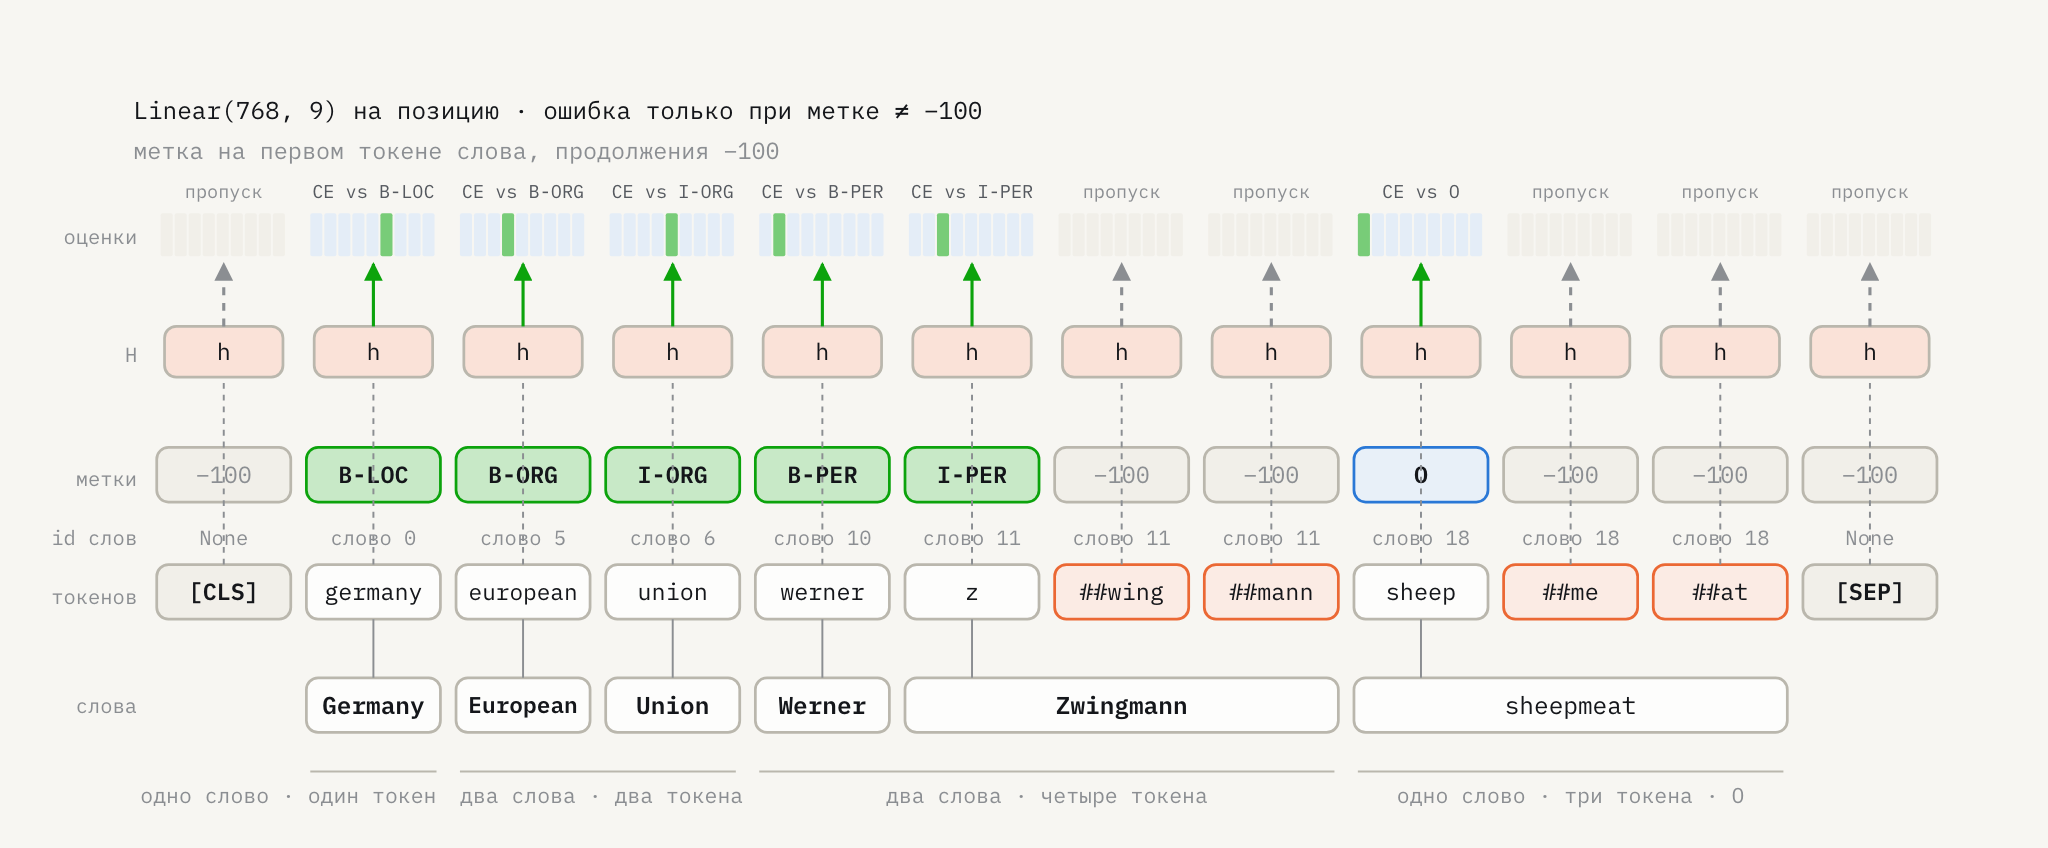

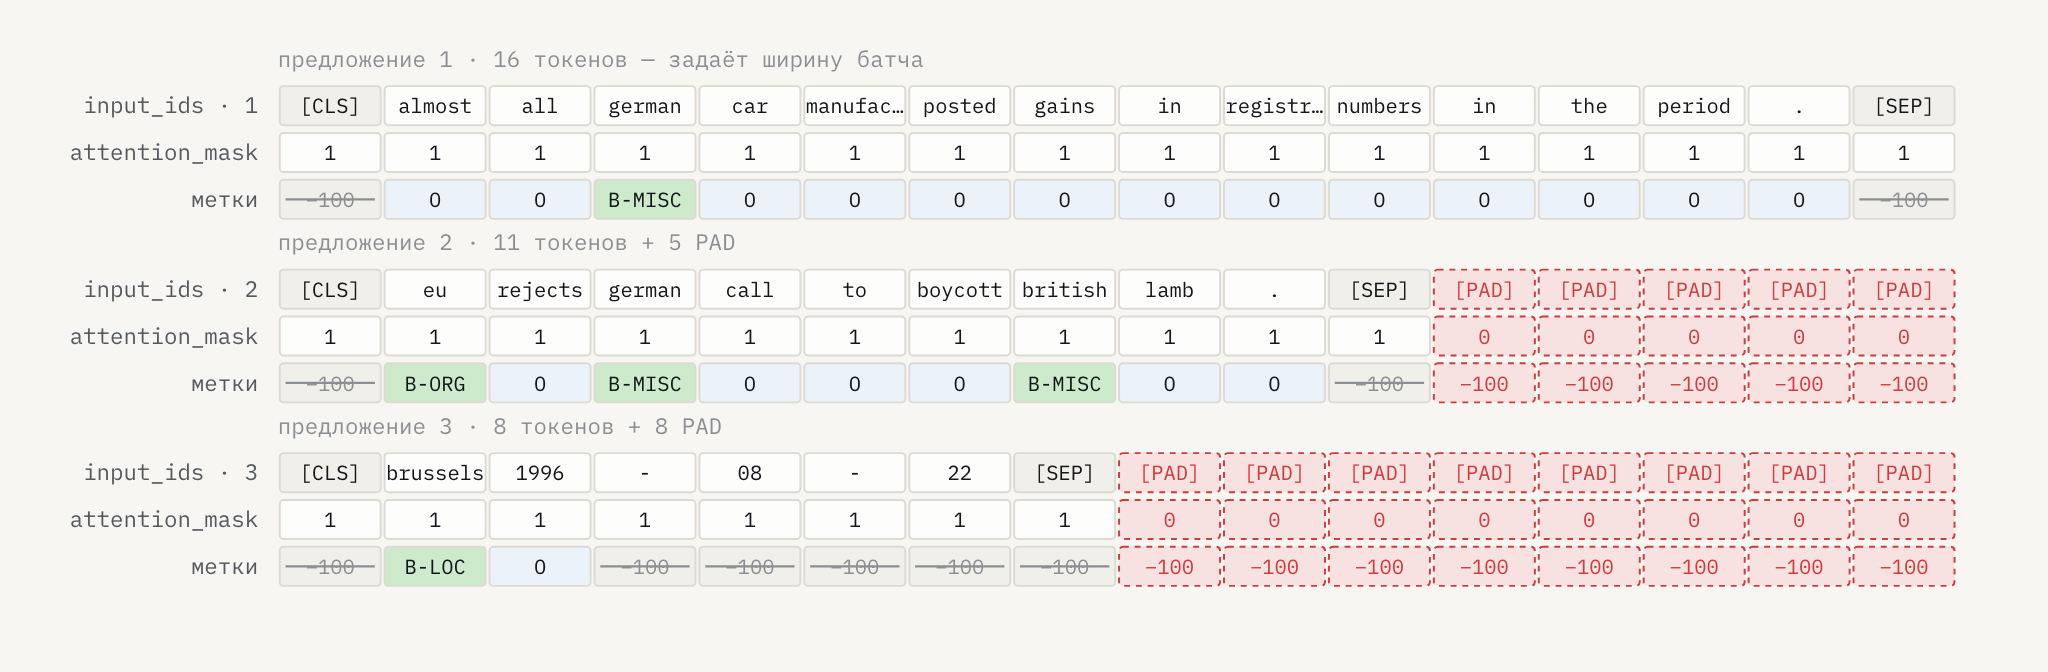


In [ ]:
def encode_ner(tokenizer, ds, max_len=160, label_continuations=False):

    def align(batch):
        enc = tokenizer(batch['tokens'], is_split_into_words=True, truncation=True, max_length=max_len)
        enc['labels'], enc['word_ids'] = ([], [])
        for i, tags in enumerate(batch['ner_tags']):
            labels, previous = ([], None)
            for word_id in enc.word_ids(i):
                if word_id is None:
                    labels.append(IGNORE)
                elif word_id != previous:
                    labels.append(tags[word_id])
                else:
                    labels.append(tags[word_id] if label_continuations else IGNORE)
                previous = word_id
            enc['labels'].append(labels)
            enc['word_ids'].append(enc.word_ids(i))
        return enc
    return ds.map(align, batched=True, remove_columns=ds.column_names)

def ner_predictions(logits, features):
    out = []
    for row, word_ids in zip(logits.argmax(-1), features['word_ids']):
        tags, previous = ([], None)
        for j, word_id in enumerate(word_ids):
            if word_id is not None and word_id != previous:
                tags.append(NER_TAGS[row[j]])
            previous = word_id
        out.append(tags)
    return out


In [ ]:
if RUN_BERT:
    ner = load_dataset("eriktks/conll2003", revision="refs/convert/parquet")
    ner_example = ner["train"].select([4, 5])
    ner_features = encode_ner(tokenizer, ner_example)
    print("Слова:", ner_example[0]["tokens"])
    print("Токены:", tokenizer.convert_ids_to_tokens(ner_features[0]["input_ids"]))
    print("Метки:", ner_features[0]["labels"])
    ner_collator = DataCollatorForTokenClassification(tokenizer)
    ner_batch = ner_collator([{k: row[k] for k in ["input_ids", "attention_mask", "token_type_ids", "labels"]} for row in ner_features])
    print("После collator:", ner_batch["labels"])
    ner_model = AutoModelForTokenClassification.from_pretrained(MODEL_NAME, num_labels=len(NER_TAGS), attn_implementation=ATTN).to(device).eval()
    with torch.no_grad():
        ner_output = ner_model(**{k: v.to(device) for k, v in ner_batch.items()})
    print("Выход:", ner_output.logits.shape, "ошибка:", ner_output.loss.item())
    print("Голова случайная; эти предсказания ещё не обучены.")
    del ner_model, ner_output, ner_batch
    free()
else:
    print("Сохранённые предсказания — в следующей ячейке; живые токены и collator: RUN_BERT = True.")


### Предсказания после обучения

Сохранённые предсказания одного и того же набора предложений позволяют сравнить обучение головы и всей модели. В интерактиве переключаем режим и смотрим типы и границы ошибок.


In [ ]:
ner_results = DATA["bert"]["ner"]["predictions"]["sentences"]
for row in ner_results[:4]:
    display(pd.DataFrame({"слово": row["words"], "только голова": row["predHeadOnly"], "вся модель": row["pred"]}))


## 4. QA: две оценки на позицию

Вход — вопрос и документ. Метка — начало и конец ответа среди токенов документа. `offset_mapping` связывает токены с символами исходного документа. Длинный документ разбивается на окна; если ответ не попал в окно, целевые позиции указывают на `[CLS]`.

**Предположение:** можно ли независимо взять лучший старт и лучший конец? Что делать, если конец оказался раньше начала?

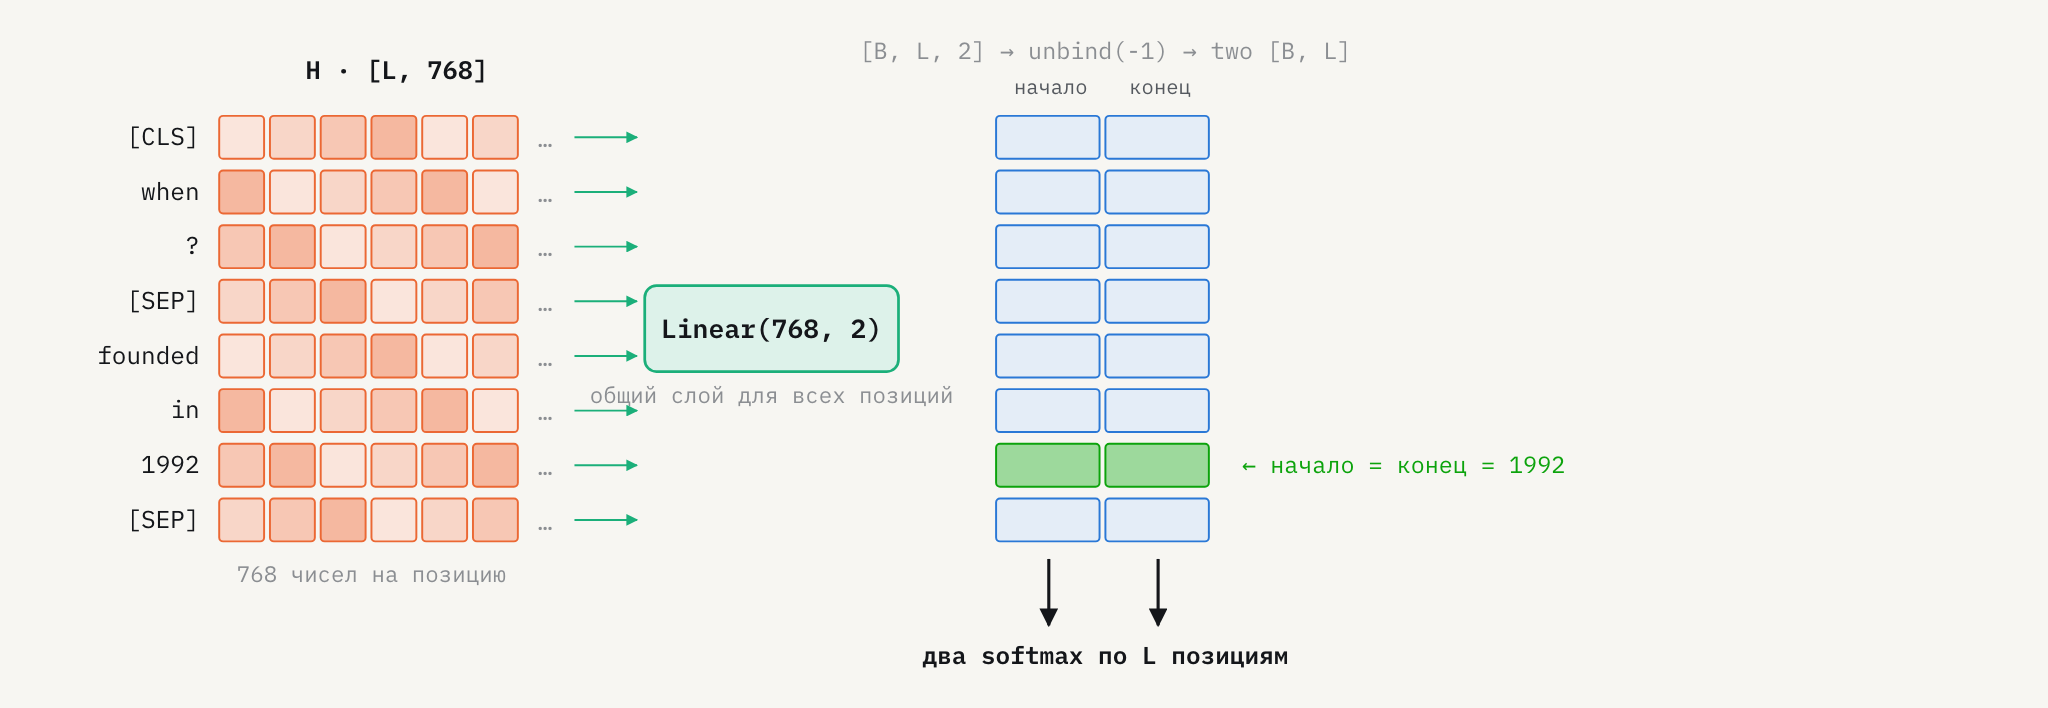

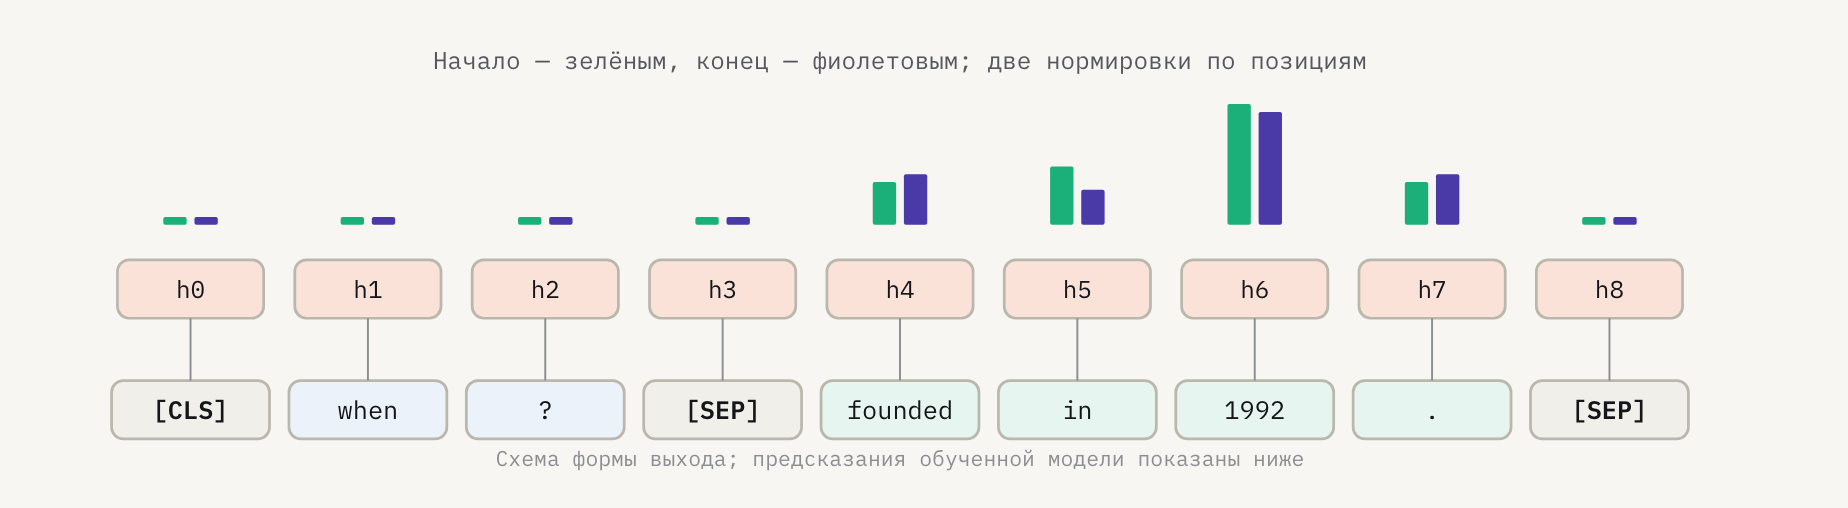

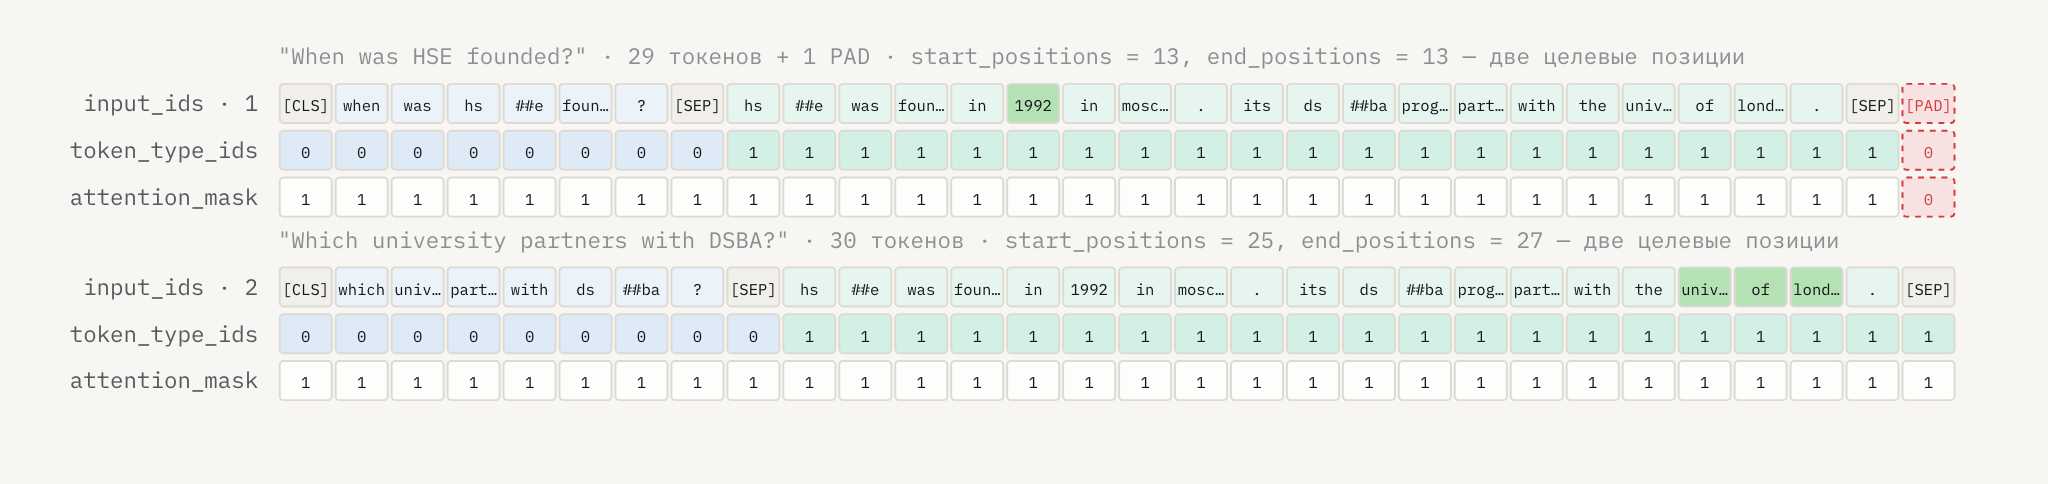


In [ ]:
def encode_qa(tokenizer, ds, max_len=384, stride=128):

    def windows(batch):
        enc = tokenizer([q.strip() for q in batch['question']], batch['context'], truncation='only_second', max_length=max_len, stride=stride, return_overflowing_tokens=True, return_offsets_mapping=True)
        sample = enc.pop('overflow_to_sample_mapping')
        enc['example_id'], enc['start_positions'], enc['end_positions'] = ([], [], [])
        for i, offsets in enumerate(enc['offset_mapping']):
            j = sample[i]
            seq_ids = enc.sequence_ids(i)
            context_tokens = [k for k, s in enumerate(seq_ids) if s == 1]
            first, last = (context_tokens[0], context_tokens[-1])
            answers = batch['answers'][j]
            start = end = 0
            if answers['text']:
                answer_start = answers['answer_start'][0]
                answer_end = answer_start + len(answers['text'][0])
                if offsets[first][0] <= answer_start and offsets[last][1] >= answer_end:
                    start = next((k for k in context_tokens if offsets[k][1] > answer_start))
                    end = next((k for k in reversed(context_tokens) if offsets[k][0] < answer_end))
            enc['example_id'].append(batch['id'][j])
            enc['start_positions'].append(start)
            enc['end_positions'].append(end)
            enc['offset_mapping'][i] = [o if s == 1 else None for o, s in zip(offsets, seq_ids)]
        return enc
    return ds.map(windows, batched=True, remove_columns=ds.column_names)

def best_span(start_scores, end_scores, offsets, max_answer_tokens=30):
    best_score, best_chars = (-1000000000.0, None)
    starts = np.argsort(start_scores)[::-1][:20]
    ends = np.argsort(end_scores)[::-1][:20]
    for s in starts:
        for e in ends:
            if offsets[s] is None or offsets[e] is None or e < s or (e - s + 1 > max_answer_tokens):
                continue
            if start_scores[s] + end_scores[e] > best_score:
                best_score, best_chars = (start_scores[s] + end_scores[e], (offsets[s][0], offsets[e][1]))
    return (best_score, best_chars)

def qa_answers(start_logits, end_logits, features, examples):
    best = {}
    for start_scores, end_scores, offsets, example_id in zip(start_logits, end_logits, features['offset_mapping'], features['example_id']):
        n = len(offsets)
        score, span = best_span(start_scores[:n], end_scores[:n], offsets)
        if span is not None and score > best.get(example_id, (-1000000000.0, None))[0]:
            best[example_id] = (score, span)
    answers = {}
    for example_id, context in zip(examples['id'], examples['context']):
        _, span = best.get(example_id, (None, None))
        answers[example_id] = '' if span is None else context[span[0]:span[1]]
    return answers


In [ ]:
if RUN_BERT:
    squad = load_dataset("rajpurkar/squad")
    qa_example = squad["validation"].select([0])
    qa_features = encode_qa(tokenizer, qa_example, max_len=128, stride=32)
    answer_text = qa_example[0]["answers"]["text"][0]
    print("Вопрос:", qa_example[0]["question"], "ответ:", answer_text)
    for row in qa_features:
        first, last = row["start_positions"], row["end_positions"]
        decoded = "вне окна" if (first, last) == (0, 0) else qa_example[0]["context"][row["offset_mapping"][first][0]:row["offset_mapping"][last][1]]
        print("Окно:", len(row["input_ids"]), "метка:", (first, last), "текст:", decoded)
    qa_model = AutoModelForQuestionAnswering.from_pretrained(MODEL_NAME, attn_implementation=ATTN).to(device).eval()
    model_inputs = {k: torch.tensor([qa_features[0][k]], device=device) for k in ["input_ids", "attention_mask", "token_type_ids"]}
    with torch.no_grad():
        qa_output = qa_model(**model_inputs)
    print("Оценки начала и конца:", qa_output.start_logits.shape, qa_output.end_logits.shape)
    print("Новая QA-голова случайная. Обученные ответы показаны отдельно.")
    del qa_model, qa_output, model_inputs
    free()
else:
    display(pd.DataFrame([{ "вопрос": e["question"], "ответ модели": e["pred"], "эталон": " / ".join(e.get("gold", [])) } for e in DATA["bert"]["qa"]["predictions"]["examples"]]))


## 5. Одна модель: base → SFT → DPO → RLVR

Сравниваем OLMo 2 1B после последовательных стадий обучения. Для base задаём текст `Question: … Answer:`, для остальных используем шаблон диалога соответствующего токенизатора. Различия выходов включают и влияние формата входа.

**Предположение:** после какой стадии модель начнёт останавливаться после ответа? После какой впервые откажется выполнять нежелательный запрос? Сначала откройте сохранённые ответы, затем попробуйте свои запросы.


In [ ]:
stages = DATA["alignment"]["stages"]
print("Сохранённый опыт:", {k: v for k, v in stages.items() if k not in ["rows", "prompts"]})
for i, prompt in enumerate(stages["prompts"]):
    print("\nЗапрос:", prompt)
    for name, row in stages["rows"].items():
        print(f"[{name}] {row['answers'][i]}")


### Какие токены предсказывает SFT

У запроса стоят метки `-100`, у ответа — токены, которые нужно предсказать. Ниже функция из исходного семинара; при включённой генерации показана маска короткого диалога через настоящий шаблон SmolLM2.

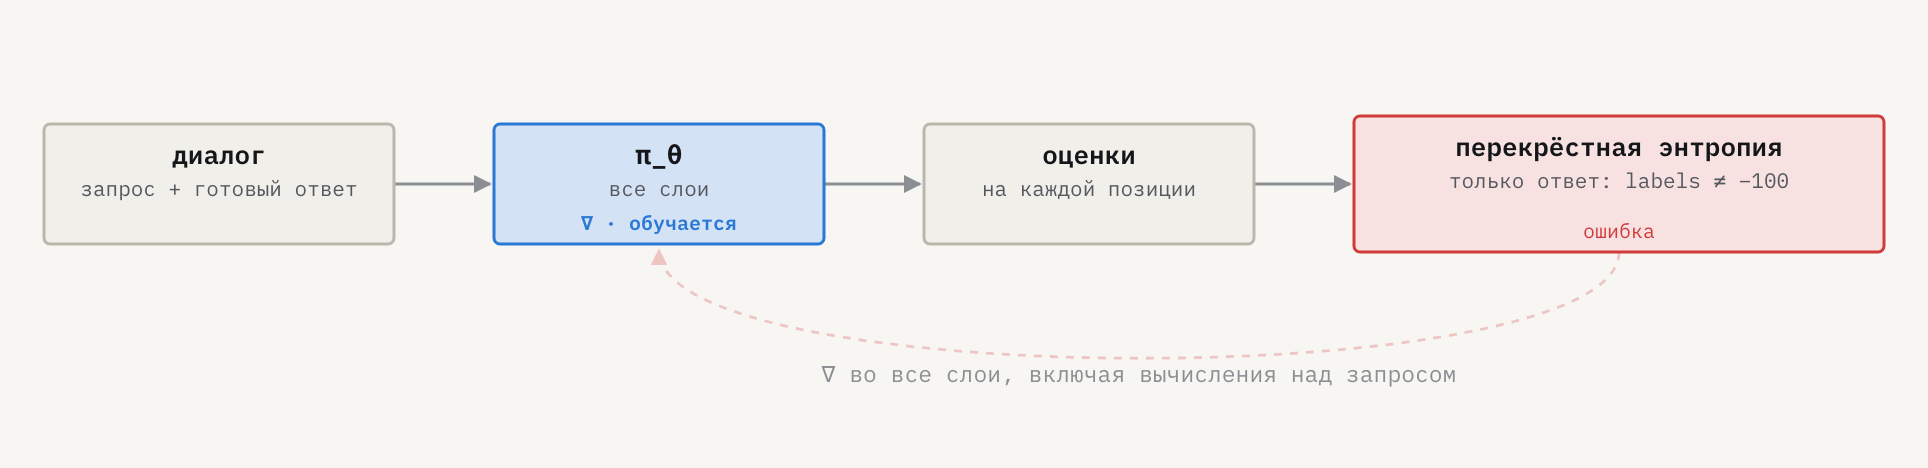


In [ ]:
def sft_example(tokenizer, messages, max_len=512, mask=True):
    prompt = tokenizer.apply_chat_template(messages[:-1], add_generation_prompt=True, tokenize=False)
    full = tokenizer.apply_chat_template(messages, tokenize=False)
    a = tokenizer(prompt, add_special_tokens=False).input_ids
    b = tokenizer(full[len(prompt):], add_special_tokens=False).input_ids
    ids = (a + b)[:max_len]
    labels = ([IGNORE] * len(a) if mask else a) + b
    return {'input_ids': ids, 'labels': labels[:max_len]}

if RUN_GENERATION:
    sft_tokenizer = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M-Instruct")
    dialogue = [{"role": "user", "content": "What is 2 + 2?"}, {"role": "assistant", "content": "4."}]
    example = sft_example(sft_tokenizer, dialogue)
    display(pd.DataFrame({"токен": sft_tokenizer.convert_ids_to_tokens(example["input_ids"]), "метка": example["labels"]}))
else:
    print("Маска SFT с настоящим токенизатором: RUN_GENERATION = True.")


In [ ]:
def as_prompt(tokenizer, question, chat=True, **template):
    if chat:
        return tokenizer.apply_chat_template([{'role': 'user', 'content': question}], add_generation_prompt=True, tokenize=False, **template)
    return f'Question: {question}\nAnswer:'


In [ ]:
STAGES = {
    "base": "allenai/OLMo-2-0425-1B",
    "SFT": "allenai/OLMo-2-0425-1B-SFT",
    "DPO": "allenai/OLMo-2-0425-1B-DPO",
    "RLVR": "allenai/OLMo-2-0425-1B-Instruct",
}
MY_PROMPTS = ["Find the value of n: n + 2 = 6. Answer in one sentence."]

if RUN_GENERATION:
    dtype = (torch.bfloat16 if device.type == "mps" or (device.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16 if device.type == "cuda" else torch.float32)
    for stage, checkpoint in STAGES.items():
        generation_tokenizer = AutoTokenizer.from_pretrained(checkpoint)
        generator = AutoModelForCausalLM.from_pretrained(checkpoint, dtype=dtype).to(device).eval()
        for question in MY_PROMPTS:
            prompt = as_prompt(generation_tokenizer, question, chat=stage != "base")
            enc = generation_tokenizer(prompt, add_special_tokens=False, return_tensors="pt").to(device)
            with torch.no_grad():
                output = generator.generate(**enc, do_sample=False, max_new_tokens=80, pad_token_id=generation_tokenizer.eos_token_id)
            print(stage, "вход:", repr(prompt))
            print(generation_tokenizer.decode(output[0, enc.input_ids.shape[1]:], skip_special_tokens=True))
        del generator, output, enc, generation_tokenizer
        free()
else:
    print("Живое сравнение четырёх чекпойнтов: RUN_GENERATION = True.")


### Инструкция и примеры в контексте

Инструкция и несколько примеров меняют вход модели. Параметры при этом остаются прежними. В отложенном материале занятия 6 сохранены продолжения GPT-2 для разных форматов запроса; здесь они доступны вместе с полными входами.

**Предположение:** если модель повторяет инструкцию, означает ли это, что инструкция изменила веса?


In [ ]:
prompt_examples = DATA["promptExamples"]
print("Условия:", {k: v for k, v in prompt_examples.items() if k != "examples"})
for example in prompt_examples["examples"]:
    print("\n", example["label"], "\nВход:\n", example["prompt"], "\nПродолжение:\n", example["output"])


## 6. LoRA: обучаем добавки к GPT-2

Классификация тональности SST-2, как в исходной практике PEFT. GPT-2 читает текст, а голова выдаёт две оценки. LoRA обучает добавки в объединённой матрице QKV `c_attn`; голова `score` тоже обучается и сохраняется.

**Предположение:** если обучаемых параметров стало во много раз меньше, станет ли шаг во столько же раз быстрее? Откройте сохранённый опыт и сравните с живым коротким запуском. У них разные условия, поэтому их скорости нельзя объединять в одну таблицу.

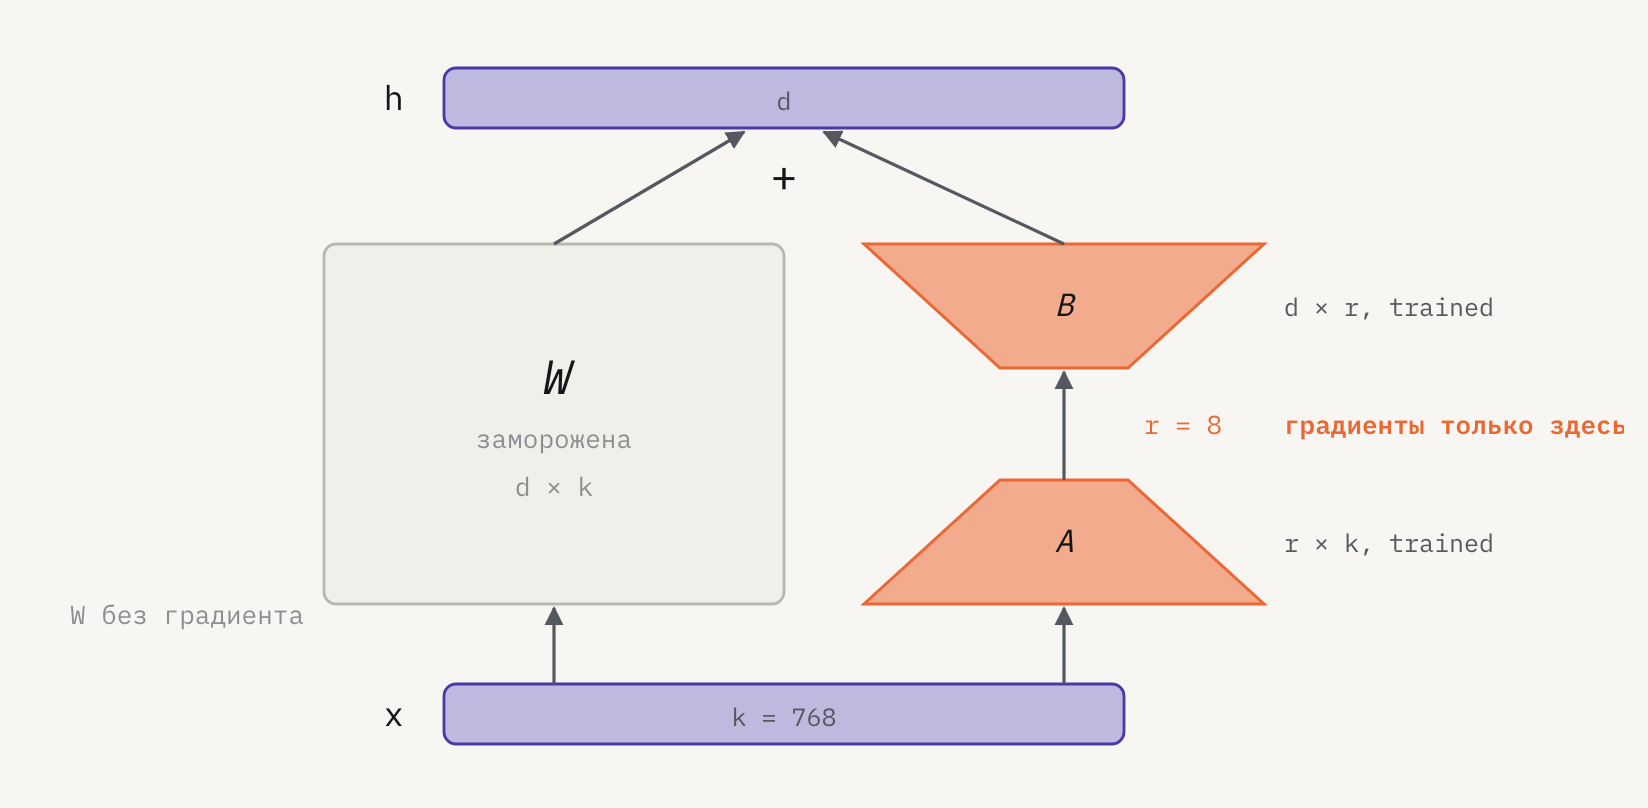


In [ ]:
print("Сохранённый опыт:", DATA["peft"]["meta"])
display(pd.DataFrame(DATA["peft"]["run"]).T)


In [ ]:
if RUN_LORA:
    lora_tokenizer = AutoTokenizer.from_pretrained("gpt2")
    lora_tokenizer.pad_token = lora_tokenizer.eos_token
    sentiment = load_dataset("glue", "sst2")
    sentiment_train = sentiment["train"].shuffle(seed=SEED).select(range(N_TRAIN))
    sentiment_test = sentiment["validation"].shuffle(seed=SEED).select(range(N_TEST))
    seed_all()
    base = AutoModelForSequenceClassification.from_pretrained("gpt2", num_labels=2, attn_implementation="eager")
    base.config.pad_token_id = lora_tokenizer.pad_token_id
    config = LoraConfig(task_type=TaskType.SEQ_CLS, r=8, lora_alpha=16, lora_dropout=0.1, target_modules=["c_attn"], modules_to_save=["score"])
    lora_model = get_peft_model(base, config).to(device)
    lora_model.print_trainable_parameters()
    sentiment_train_loader, sentiment_test_loader = classification_data(lora_tokenizer, sentiment_train, sentiment_test, "sentence")
    print("До:", classification_score(lora_model, sentiment_test_loader))
    lora_losses = fit_classifier(lora_model, sentiment_train_loader, lr=1e-4)
    print("После:", classification_score(lora_model, sentiment_test_loader))
else:
    print("Обучение LoRA: RUN_LORA = True.")


### Сохранение, загрузка и слияние

`save_pretrained` сохраняет адаптер и указанную в `modules_to_save` голову. Для загрузки нужна та же основа. После слияния сравниваем выходы на одном батче с выключенным dropout.


In [ ]:
if RUN_LORA:
    adapter_path = OUTPUT_DIR / "gpt2-sst2-lora"
    lora_model.eval()
    probe_batch = lora_tokenizer(["The film was wonderful.", "An awful movie."], padding=True, return_tensors="pt").to(device)
    with torch.no_grad():
        expected_logits = lora_model(**probe_batch).logits.cpu()
    lora_model.save_pretrained(adapter_path)
    lora_tokenizer.save_pretrained(adapter_path)
    del lora_model, base
    free()
    reloaded_base = AutoModelForSequenceClassification.from_pretrained("gpt2", num_labels=2, attn_implementation="eager")
    reloaded_base.config.pad_token_id = lora_tokenizer.pad_token_id
    restored = PeftModel.from_pretrained(reloaded_base, adapter_path).to(device).eval()
    with torch.no_grad():
        restored_logits = restored(**probe_batch).logits.cpu()
    torch.testing.assert_close(expected_logits, restored_logits, atol=1e-5, rtol=1e-5)
    merged = restored.merge_and_unload().eval()
    with torch.no_grad():
        merged_logits = merged(**probe_batch).logits.cpu()
    torch.testing.assert_close(restored_logits, merged_logits, atol=1e-4, rtol=1e-4)
    print("Выходы после загрузки и слияния совпали в заданном допуске.")
    print("Файлы:", [p.name for p in adapter_path.iterdir()])
    del restored, merged, reloaded_base, probe_batch
    free()


## 7. PPO, DPO и GRPO: один настоящий шаг обновления

Ниже маленькая policy выбирает один из двух целых ответов на запрос. Это **учебная задача с конечным набором ответов**: она позволяет выполнить градиентное обновление на CPU и прочитать все вероятности. У языковой модели вместо одного выбора — последовательность токенов.

PPO использует обучаемый critic, замороженную модель награды и reference; DPO — готовую пару и reference; GRPO — группу собственных ответов и программу проверки. Эти шаги проверяют вычисления, а не обучают полноценного ассистента.


In [ ]:
def ppo_surrogate(log_probs, old_log_probs, advantages, epsilon=0.2):
    ratio = (log_probs - old_log_probs).exp()
    return torch.minimum(ratio * advantages, ratio.clamp(1-epsilon, 1+epsilon) * advantages)


def dpo_loss(chosen, rejected, ref_chosen, ref_rejected, beta=0.1):
    margin = beta * ((chosen - ref_chosen) - (rejected - ref_rejected))
    return -F.logsigmoid(margin).mean()


def group_advantages(rewards, epsilon=1e-6):
    return (rewards - rewards.mean(-1, keepdim=True)) / (rewards.std(-1, keepdim=True, correction=0) + epsilon)


def exact_kl(logits, reference_logits):
    log_policy = logits.log_softmax(-1)
    return (log_policy.exp() * (log_policy - reference_logits.log_softmax(-1))).sum(-1).mean()


class AnswerPolicy(nn.Module):
    def __init__(self):
        super().__init__()
        self.logits = nn.Parameter(torch.zeros(2, 2))

    def forward(self):
        return self.logits


# По одному правильному ответу на каждый из двух запросов.
VERIFIER = torch.tensor([[1.0, 0.0], [0.0, 1.0]])
BETA = 0.05


### PPO

В этой задаче ответ занимает один шаг. Поэтому advantage — награда с KL-поправкой минус предсказание critic. При обновлении policy advantage считается константой. Для critic используется отдельная квадратичная ошибка.

**Предположение:** у какого из четырёх компонентов изменятся параметры? Проверьте по выходу.

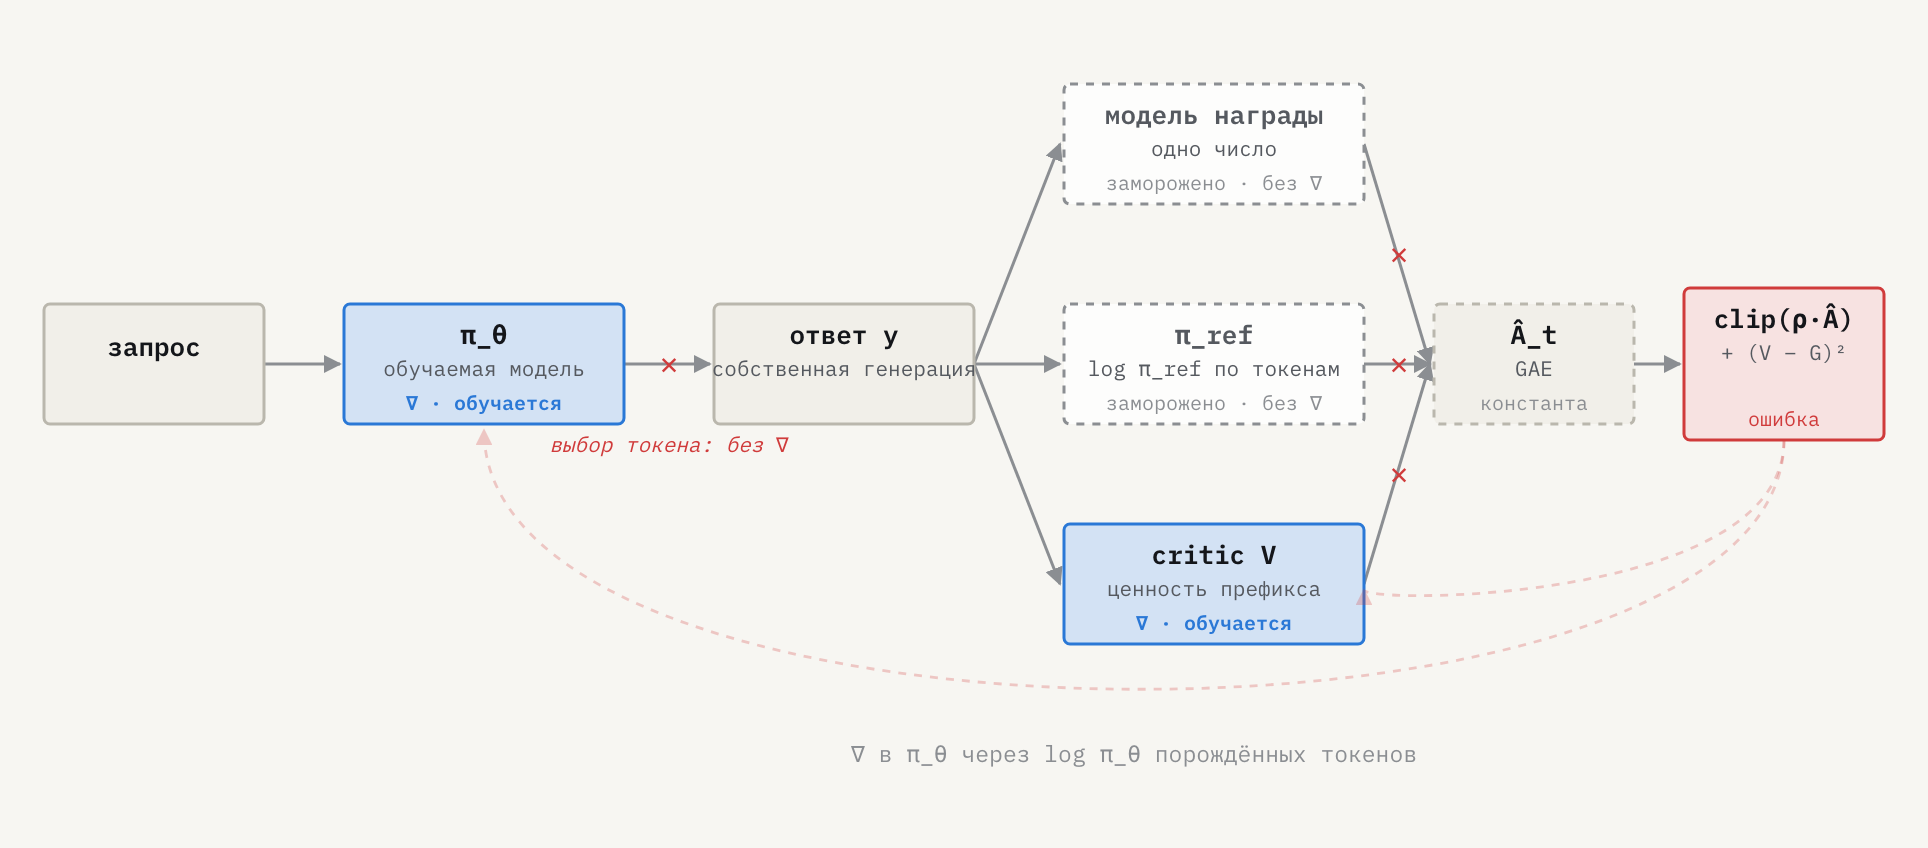


In [ ]:
seed_all()
ppo_policy = AnswerPolicy()
ppo_reference = ppo_policy().detach().clone()
critic = nn.Parameter(torch.zeros(2))
reward_model = nn.Embedding.from_pretrained(torch.tensor([[0.9], [0.1], [0.1], [0.9]]), freeze=True)
optimizer = torch.optim.Adam([*ppo_policy.parameters(), critic], lr=0.1)
with torch.no_grad():
    old_log = ppo_policy().log_softmax(-1)
    sampled = torch.distributions.Categorical(logits=ppo_policy()).sample((16,)).T
    requests = torch.arange(2)[:, None]
    old_selected = old_log.gather(1, sampled)
    rewards = reward_model((2 * requests + sampled).flatten()).reshape_as(sampled)
    ref_selected = ppo_reference.log_softmax(-1).gather(1, sampled)
    returns = rewards - BETA * (old_selected - ref_selected)
    advantage = returns - critic[:, None]
for epoch in range(3):
    selected = ppo_policy().log_softmax(-1).gather(1, sampled)
    policy_loss = -ppo_surrogate(selected, old_selected, advantage).mean()
    value_loss = F.mse_loss(critic[:, None].expand_as(returns), returns)
    loss = policy_loss + 0.5 * value_loss
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
print("PPO, вероятности:", ppo_policy().softmax(-1).detach())
print("Critic:", critic.detach())
print("Reference:", ppo_reference.softmax(-1))
print("Модель награды обучается:", reward_model.weight.requires_grad)


### DPO

Для первого запроса выбран ответ 0, для второго — ответ 1. Новые ответы внутри шага не порождаются. Reference хранит исходные вероятности пары.

**Предположение:** может ли ошибка уменьшиться, когда вероятности обоих ответов падают? Проверьте на калькуляторе лекции.

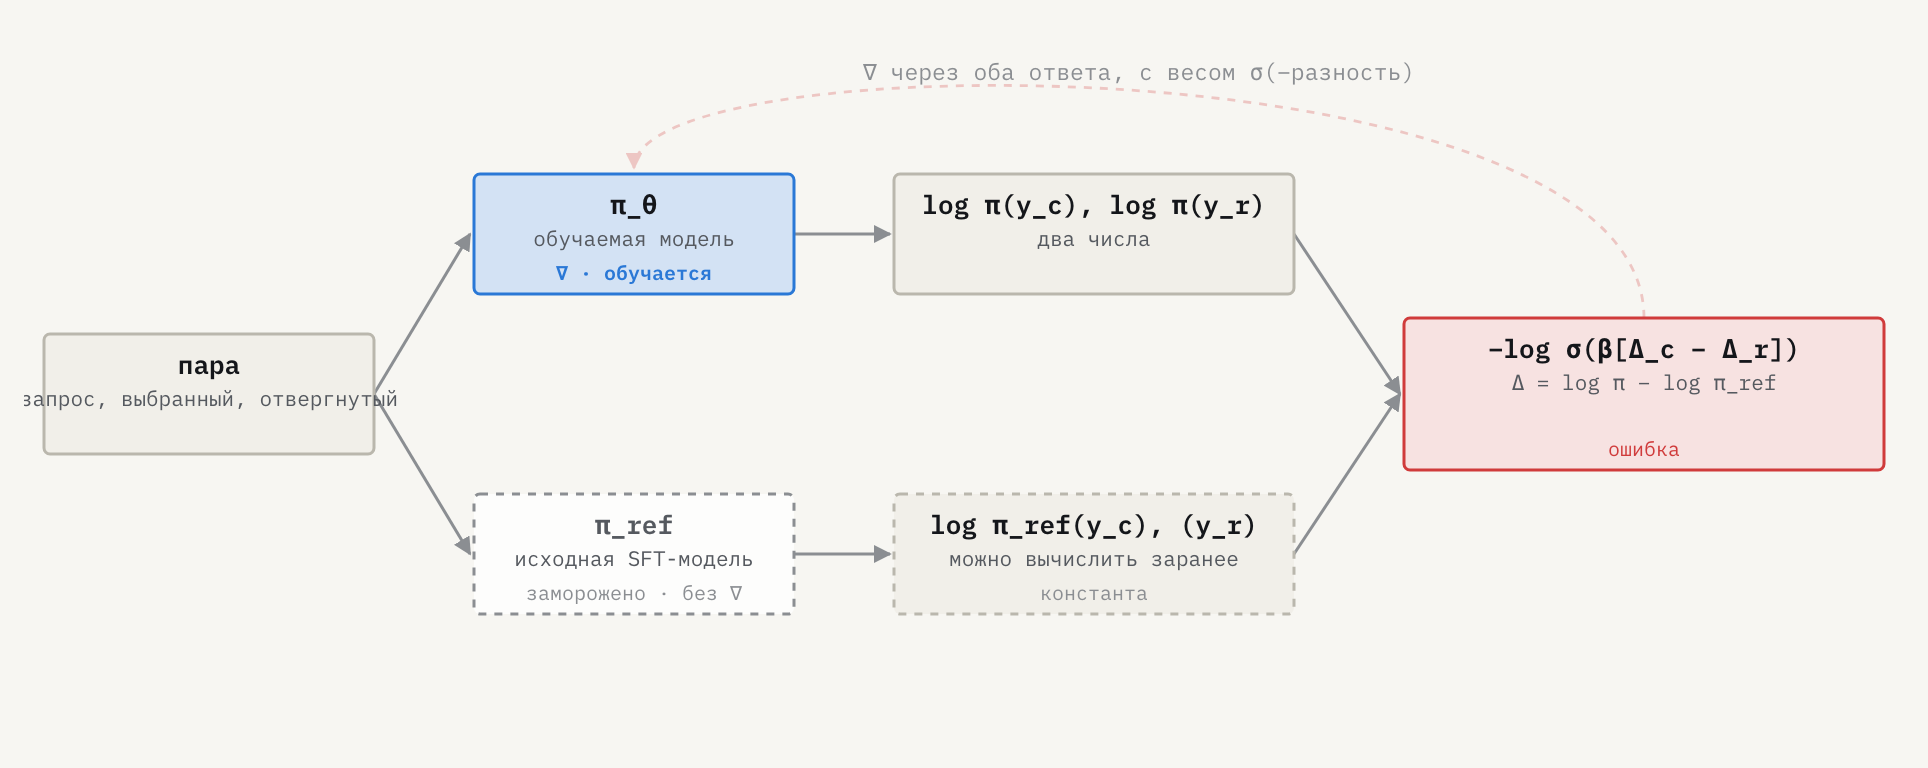


In [ ]:
dpo_policy = AnswerPolicy()
dpo_reference = dpo_policy().detach().clone()
optimizer = torch.optim.Adam(dpo_policy.parameters(), lr=0.1)
chosen = torch.tensor([0, 1])
rejected = 1 - chosen
requests = torch.arange(2)
log_probs = dpo_policy().log_softmax(-1)
ref_log_probs = dpo_reference.log_softmax(-1)
loss = dpo_loss(log_probs[requests, chosen], log_probs[requests, rejected], ref_log_probs[requests, chosen], ref_log_probs[requests, rejected])
optimizer.zero_grad()
loss.backward()
optimizer.step()
print("DPO, ошибка:", loss.item(), "вероятности:", dpo_policy().softmax(-1).detach())


### GRPO с проверяемой наградой

На каждый запрос порождаем группу ответов. Программа выставляет награду, среднее группы служит baseline. В шаге используется то же ограничение отношения вероятностей, что в PPO, и отдельный KL к reference.

**Предположение:** что будет с сигналом от награды, если вся группа получила единицы? А нули? Отдельно проверьте KL при отличающейся policy.

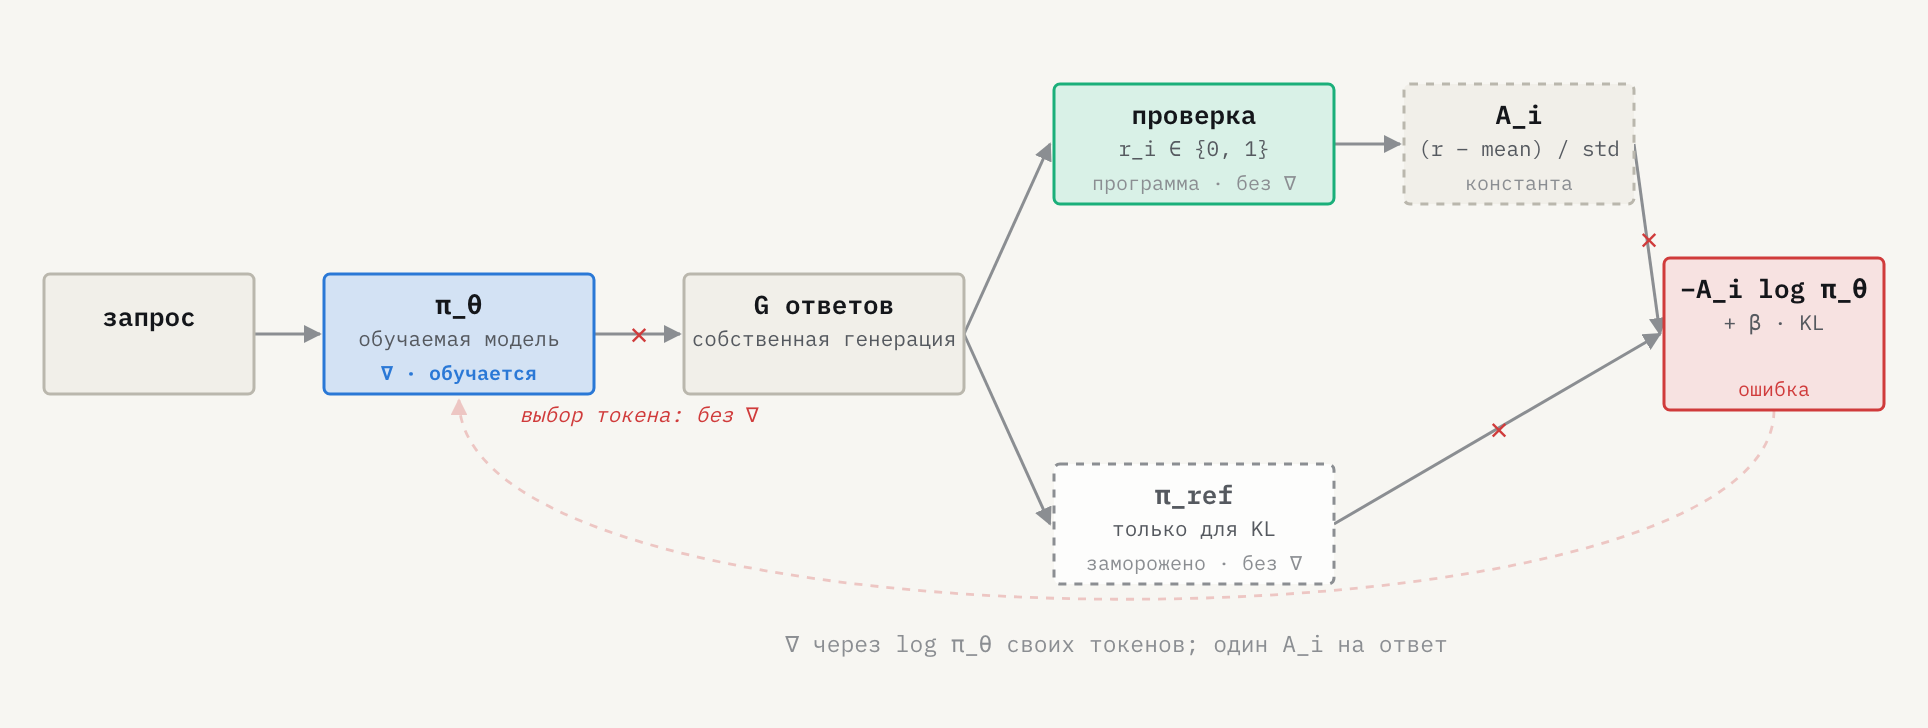


In [ ]:
seed_all()
grpo_policy = AnswerPolicy()
grpo_reference = grpo_policy().detach().clone()
optimizer = torch.optim.Adam(grpo_policy.parameters(), lr=0.1)
with torch.no_grad():
    old_log = grpo_policy().log_softmax(-1)
    sampled = torch.distributions.Categorical(logits=grpo_policy()).sample((16,)).T
    requests = torch.arange(2)[:, None]
    rewards = VERIFIER[requests, sampled]
    advantage = group_advantages(rewards)
    old_selected = old_log.gather(1, sampled)
selected = grpo_policy().log_softmax(-1).gather(1, sampled)
loss = -ppo_surrogate(selected, old_selected, advantage).mean() + BETA * exact_kl(grpo_policy(), grpo_reference)
optimizer.zero_grad()
loss.backward()
optimizer.step()
print("GRPO, награды:", rewards)
print("Advantages:", advantage)
print("Вероятности:", grpo_policy().softmax(-1).detach())
print("Одинаковые награды:", group_advantages(torch.ones(1, 8)))


## Что проверить самостоятельно

1. Замените слова классов в zero-shot BERT и разберите ошибки по классам.
2. Найдите слово из нескольких токенов и проверьте метки NER после collator.
3. Подберите QA-пример, ответ которого находится в другом окне.
4. Дайте четырём стадиям OLMo одно требование к формату; отдельно оцените правильность и формат.
5. Измените ранг LoRA, сохранив данные, seed и бюджет обучения. Сохраните и загрузите адаптер.
6. В шагах PPO и GRPO увеличьте обновление и посмотрите на clipping. В DPO проверьте роль reference.

## Источники

* Devlin et al. (2019). [*BERT.*](https://arxiv.org/abs/1810.04805) NAACL.
* Hu et al. (2021). [*LoRA.*](https://arxiv.org/abs/2106.09685) ICLR 2022.
* Schulman et al. (2017). [*Proximal Policy Optimization Algorithms.*](https://arxiv.org/abs/1707.06347) arXiv.
* Rafailov et al. (2023). [*Direct Preference Optimization.*](https://arxiv.org/abs/2305.18290) NeurIPS.
* Shao et al. (2024). [*DeepSeekMath.*](https://arxiv.org/abs/2402.03300) arXiv.
* Lambert et al. (2024). [*Tülu 3.*](https://arxiv.org/abs/2411.15124) arXiv.
* Team OLMo (2025). [*2 OLMo 2 Furious.*](https://arxiv.org/abs/2501.00656) arXiv.
